# Notebook 01: Data Understanding & Initial Inspection


In [1]:
# 1. Standard Library and Data Processing Imports
import os
import sys
import time
from pathlib import Path

# Core Numerical and Scientific Computing
import pandas as pd
import numpy as np

# Visualization Libraries
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Jupyter Display Options
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: "%.2f" % x)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

print("All required analytical libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")


All required analytical libraries imported successfully!
Pandas version: 2.2.2
NumPy version: 1.25.0


## Section 1: Configuration & File Path Validation

### What we are doing:
We configure relative file paths pointing to the raw datasets on disk and verify their presence.

### Why we are doing it:
Hardcoding absolute paths (e.g., `C:\Users\...`) causes code to fail on other machines, in Docker containers, and in cloud environments. Using `pathlib.Path` with relative anchors makes the pipeline reproducible.

### How it works:
We define configuration constants and check each file's existence using `.exists()`.


In [2]:
# Define dataset paths relative to the project root
PROJECT_ROOT = Path(".").resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW_DIR = PROJECT_ROOT / "data" / "raw"
ARCHIVE_DIR = PROJECT_ROOT / "archive"
HM_DIR = PROJECT_ROOT / "h-and-m-personalized-fashion-recommendations"

# Individual dataset file paths
MYNTRA_CSV_PATH = ARCHIVE_DIR / "Myntra Fasion Clothing.csv"
if not MYNTRA_CSV_PATH.exists():
    MYNTRA_CSV_PATH = DATA_RAW_DIR / "Myntra Fasion Clothing.csv"

HM_ARTICLES_PATH = HM_DIR / "articles.csv"
HM_CUSTOMERS_PATH = HM_DIR / "customers.csv"
HM_TRANSACTIONS_PATH = HM_DIR / "transactions_train.csv"
HM_IMAGE_DIR = HM_DIR / "images"

# Validate presence of each dataset file
paths_to_verify = {
    "Myntra Catalog CSV": MYNTRA_CSV_PATH,
    "H&M Articles CSV": HM_ARTICLES_PATH,
    "H&M Customers CSV": HM_CUSTOMERS_PATH,
    "H&M Transactions CSV": HM_TRANSACTIONS_PATH,
    "H&M Images Directory": HM_IMAGE_DIR
}

print("Verifying dataset paths on disk:")
for name, p in paths_to_verify.items():
    status = "EXISTS (OK)" if p.exists() else "MISSING (CHECK PATH)"
    print(f"  - {name:22s} -> {str(p):60s} [{status}]")
    assert p.exists(), f"Critical file missing: {p}"

print("\nAll dataset paths verified successfully!")


Verifying dataset paths on disk:
  - Myntra Catalog CSV     -> H:\AURA ML-SD\archive\Myntra Fasion Clothing.csv             [EXISTS (OK)]
  - H&M Articles CSV       -> H:\AURA ML-SD\h-and-m-personalized-fashion-recommendations\articles.csv [EXISTS (OK)]
  - H&M Customers CSV      -> H:\AURA ML-SD\h-and-m-personalized-fashion-recommendations\customers.csv [EXISTS (OK)]
  - H&M Transactions CSV   -> H:\AURA ML-SD\h-and-m-personalized-fashion-recommendations\transactions_train.csv [EXISTS (OK)]
  - H&M Images Directory   -> H:\AURA ML-SD\h-and-m-personalized-fashion-recommendations\images [EXISTS (OK)]

All dataset paths verified successfully!


## Inspecting  H&M Articles Catalog

### What we are doing:
We load `articles.csv` from the H&M dataset, ensuring the `article_id` is zero-padded to 10 digits as a string (e.g. `0108775015`).

### Why we are doing it:
The raw article IDs are 10-digit codes where leading zeros are semantically meaningful and correspond to the image file names on disk. Loading as integer strips leading zeros and breaks image lookups.


In [6]:
# Load H&M articles with explicit string type for article_id
t0 = time.time()
df_articles = pd.read_csv(HM_ARTICLES_PATH, dtype={"article_id": str})
df_articles["article_id"] = df_articles["article_id"].str.zfill(10)
load_duration = time.time() - t0

print(f"H&M Articles loaded in {load_duration:.2f} seconds.")
print(f"Total Articles: {df_articles.shape[0]:,}")
print(f"Total Columns: {df_articles.shape[1]}")
print(f"Memory Usage: {df_articles.memory_usage(deep=True).sum() / (1024**2):.2f} MB\n")

# Display first 3 records with key hierarchical columns
display(df_articles[[
    "article_id", "prod_name", "product_type_name", "product_group_name",
    "colour_group_name", "perceived_colour_value_name", "department_name", "index_group_name"
]].head(3))


H&M Articles loaded in 0.87 seconds.
Total Articles: 105,542
Total Columns: 25
Memory Usage: 123.52 MB



,article_id,prod_name,product_type_name,product_group_name,colour_group_name,perceived_colour_value_name,department_name,index_group_name
0,0108775015,Strap top,Vest top,Garment Upper body,Black,Dark,Jersey Basic,Ladieswear
1,0108775044,Strap top,Vest top,Garment Upper body,White,Light,Jersey Basic,Ladieswear
2,0108775051,Strap top (1),Vest top,Garment Upper body,Off White,Dusty Light,Jersey Basic,Ladieswear


### H&M Hierarchical Taxonomy Analysis

### What we are doing:
We inspect the multi-level taxonomy provided by H&M:
- **`product_group_name`**: Highest level functional category (Upper body, Lower body, Full body, Shoes, Accessories).
- **`product_type_name`**: Specific garment type (Trousers, Dress, T-shirt, Jacket, etc.).
- **`colour_group_name`** and **`perceived_colour_value_name`**: Color attributes essential for outfit color harmony.

### Why this is critical for Outfit Compatibility:
A complete outfit requires selecting compatible slots: 1 Upper Body item + 1 Lower Body item + 1 Shoes + optional Accessories. H&M's taxonomy gives us the exact category slots required for this logic.


C:\Users\Harshal\AppData\Local\Temp\ipykernel_4392\2146083896.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_prod_groups.values, y=top_prod_groups.index, ax=axes[0], palette="crest")
C:\Users\Harshal\AppData\Local\Temp\ipykernel_4392\2146083896.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_colours.values, y=top_colours.index, ax=axes[1], palette="rocket")


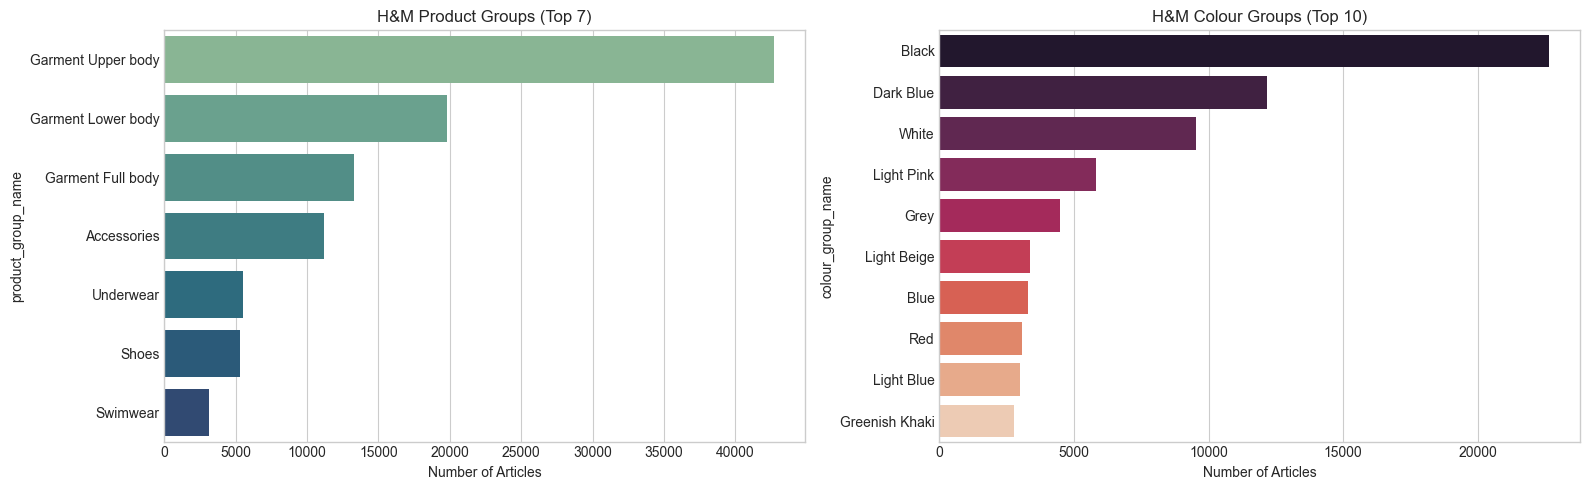

H&M Product Groups Breakdown:


,Count,Percentage (%)
product_group_name,,
Garment Upper body,42741,40.50
Garment Lower body,19812,18.77
Garment Full body,13292,12.59
Accessories,11158,10.57
Underwear,5490,5.20
Shoes,5283,5.01
Swimwear,3127,2.96
Socks & Tights,2442,2.31
Nightwear,1899,1.80


In [7]:
# Explore product groups and color groups
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Top Product Groups
top_prod_groups = df_articles["product_group_name"].value_counts().head(7)
sns.barplot(x=top_prod_groups.values, y=top_prod_groups.index, ax=axes[0], palette="crest")
axes[0].set_title("H&M Product Groups (Top 7)")
axes[0].set_xlabel("Number of Articles")

# Top Colour Groups
top_colours = df_articles["colour_group_name"].value_counts().head(10)
sns.barplot(x=top_colours.values, y=top_colours.index, ax=axes[1], palette="rocket")
axes[1].set_title("H&M Colour Groups (Top 10)")
axes[1].set_xlabel("Number of Articles")

plt.tight_layout()
plt.show()

# Print detailed summary of product groups
print("H&M Product Groups Breakdown:")
display(pd.DataFrame({
    "Count": df_articles["product_group_name"].value_counts(),
    "Percentage (%)": (df_articles["product_group_name"].value_counts(normalize=True) * 100).round(2)
}))


## Section 4: H&M Image Matching & Visual Validation

### What we are doing:
We scan the local `images/` folder on disk, map each image filename to its corresponding `article_id`, and verify the image match rate. We also load and display sample images.

### Why we are doing it:
In our dataset audit, we observed that 105,100 of 105,542 articles (99.58%) have images. We must verify this directly in the notebook and confirm image readability using PIL.


Total image files found on disk: 105,102
Articles with verified local images: 105,100 / 105,542 (99.58%)
Articles missing images: 442


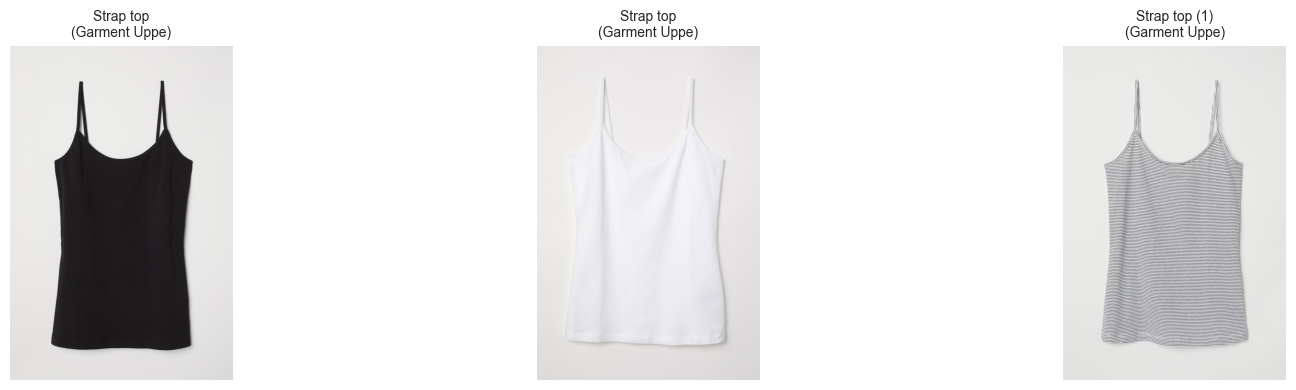

In [8]:
# Scan local images directory
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}
image_paths = [p for p in HM_IMAGE_DIR.rglob("*") if p.is_file() and p.suffix.lower() in image_extensions]

# Build lookup dictionary mapping article_id -> file path
image_lookup = {p.stem: str(p) for p in image_paths}

# Map onto df_articles
df_articles["image_path"] = df_articles["article_id"].map(image_lookup)
matched_count = df_articles["image_path"].notna().sum()
total_articles = len(df_articles)
match_pct = (matched_count / total_articles) * 100

print(f"Total image files found on disk: {len(image_paths):,}")
print(f"Articles with verified local images: {matched_count:,} / {total_articles:,} ({match_pct:.2f}%)")
print(f"Articles missing images: {total_articles - matched_count:,}")

# Display a grid of 6 sample products with images
sample_articles = df_articles[df_articles["image_path"].notna()].head(6)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (_, row) in zip(axes, sample_articles.iterrows()):
    with Image.open(row["image_path"]) as img:
        ax.imshow(img.convert("RGB"))
    ax.set_title(f"{row['prod_name'][:16]}\n({row['product_group_name'][:12]})", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

assert match_pct > 99.0, f"Expected >99% image coverage, found {match_pct:.2f}%"


## Section 5: Inspecting H&M Customers & Demographics

### What we are doing:
We inspect `customers.csv` containing 1,371,980 customer records, checking the age distribution, club membership status, and fashion news frequency.


Total Customer Profiles: 1,371,980
Total Columns: 7
Missing Age values: 15,861 (1.16%)



C:\Users\Harshal\AppData\Local\Temp\ipykernel_2940\569794733.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=member_status.values, y=member_status.index.astype(str), ax=axes[1], palette="Set2")


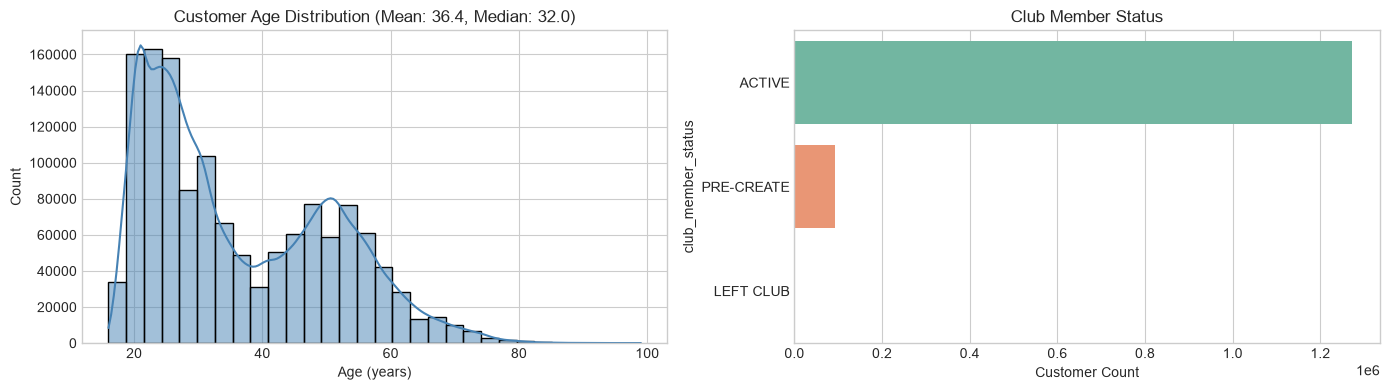

In [9]:
# Load customers dataset
df_customers = pd.read_csv(HM_CUSTOMERS_PATH)

print(f"Total Customer Profiles: {df_customers.shape[0]:,}")
print(f"Total Columns: {df_customers.shape[1]}")
print(f"Missing Age values: {df_customers['age'].isna().sum():,} ({df_customers['age'].isna().mean()*100:.2f}%)\n")

# Customer Demographics Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Age Distribution
sns.histplot(df_customers["age"].dropna(), bins=30, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"Customer Age Distribution (Mean: {df_customers['age'].mean():.1f}, Median: {df_customers['age'].median():.1f})")
axes[0].set_xlabel("Age (years)")

# Club Member Status
member_status = df_customers["club_member_status"].value_counts(dropna=False)
sns.barplot(x=member_status.values, y=member_status.index.astype(str), ax=axes[1], palette="Set2")
axes[1].set_title("Club Member Status")
axes[1].set_xlabel("Customer Count")

plt.tight_layout()
plt.show()


## Section 6: H&M Transactions Scope & Temporal Coverage

### What we are doing:
We inspect the transaction log boundary dates without loading the entire 3.48 GB CSV into memory at once. We verify the date range (2018-09-20 to 2020-09-22) and the recommended 16-week window.


In [10]:
# Inspect transaction bounds efficiently using chunking
min_date = None
max_date = None
tx_count = 0

chunk_size = 2_000_000
for chunk in pd.read_csv(HM_TRANSACTIONS_PATH, usecols=["t_dat"], chunksize=chunk_size):
    tx_count += len(chunk)
    c_min = chunk["t_dat"].min()
    c_max = chunk["t_dat"].max()
    min_date = c_min if min_date is None else min(min_date, c_min)
    max_date = c_max if max_date is None else max(max_date, c_max)

print(f"Total Transactions in dataset: {tx_count:,}")
print(f"Start Date: {min_date}")
print(f"End Date:   {max_date}")

# Calculate 16-week sampling start date
max_dt = pd.to_datetime(max_date)
start_16w = (max_dt - pd.Timedelta(weeks=16)).strftime("%Y-%m-%d")
print(f"Selected 16-Week Sampling Window: {start_16w} to {max_date}")


Total Transactions in dataset: 31,788,324
Start Date: 2018-09-20
End Date:   2020-09-22
Selected 16-Week Sampling Window: 2020-06-02 to 2020-09-22


## Section 7: Formal Integrity Assertions & Stage Sign-Off

### What we are doing:
We run formal assertions verifying that all datasets meet the strict quality thresholds required by our ML pipeline.

### Validation Checks:
1. Myntra contains 526,564 unique product records with zero ID duplicates.
2. H&M articles contain 105,542 unique articles with zero ID duplicates.
3. H&M image coverage is greater than 99.5%.
4. H&M transaction log covers 2018-09-20 through 2020-09-22.
5. All required feature columns are present.


In [11]:
# Formal Validation Checks
print("Executing Stage 1 Formal Validation Assertions...")

# 1. Myntra Checks
assert len(df_myntra) == 526564, f"Unexpected Myntra row count: {len(df_myntra)}"
assert df_myntra["Product_id"].nunique() == 526564, "Myntra Product_id contains duplicates!"
assert "BrandName" in df_myntra.columns and "Category" in df_myntra.columns, "Myntra missing required columns"

# 2. H&M Articles Checks
assert len(df_articles) == 105542, f"Unexpected H&M article count: {len(df_articles)}"
assert df_articles["article_id"].nunique() == 105542, "H&M article_id contains duplicates!"
assert match_pct >= 99.5, f"Image match rate below threshold: {match_pct:.2f}%"

# 3. H&M Customer Checks
assert len(df_customers) == 1371980, f"Unexpected Customer count: {len(df_customers)}"

# 4. H&M Transaction Bounds
assert min_date == "2018-09-20" and max_date == "2020-09-22", "Transaction date bounds mismatch"
assert tx_count == 31788324, f"Unexpected transaction count: {tx_count}"

print("=" * 60)
print("ALL VALIDATION CHECKS PASSED SUCCESSFULLY (100% OK)")
print("Notebook 01 execution complete. Ready for Notebook 02: Data Cleaning & EDA.")
print("=" * 60)


Executing Stage 1 Formal Validation Assertions...
ALL VALIDATION CHECKS PASSED SUCCESSFULLY (100% OK)
Notebook 01 execution complete. Ready for Notebook 02: Data Cleaning & EDA.
